<a href="https://colab.research.google.com/github/Madihasafi/ITC-300-Data-Visualization-/blob/main/Madiha_Safi%2C_w11p2_Visualizing_Multiple_Distributions_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ITC 300: Data Visualization**
## **w11p2: Visualizing Multiple Distributions**


# **Section 0: Data preparation**

## 0.1 Import the required libraries

- **pandas** manages tables, cleaning, grouping, and reshaping.
- **NumPy** creates numerical sequences and supports calculations.
- **Matplotlib** provides the base plotting objects.
- **Seaborn** provides statistical plots and consistent styling.
- **SciPy** supplies the kernel density estimator used in the ridgeline plot.


In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import StrMethodFormatter

try:
    from IPython.display import display
except ImportError:
    def display(*objects):
        for obj in objects:
            print(obj)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

months = [
    "JANUARY", "FEBRUARY", "MARCH", "APRIL",
    "MAY", "JUNE", "JULY", "AUGUST",
    "SEPTEMBER", "OCTOBER", "NOVEMBER", "DECEMBER"
]

quarter_order = ["Q1", "Q2", "Q3", "Q4"]

print("Libraries imported successfully.")


Libraries imported successfully.


## 0.2 Upload and load the Sales dataset

The next cell first looks for `Sales(2).csv` or `Sales.csv` in the current session. If neither file exists, Google Colab opens an upload dialog. The file is initially read with `dtype=str` so that cleaning decisions remain explicit. Reading mixed fields as text prevents pandas from interpreting some placeholders differently from others before we inspect them.


In [4]:
csv_candidates = [Path("Sales.csv")]
csv_path = next((path for path in csv_candidates if path.exists()), None)

if csv_path is None:
    from google.colab import files

    uploaded = files.upload()
    csv_path = Path(next(iter(uploaded)))

raw = pd.read_csv(csv_path, dtype=str)

print(f"Loaded file: {csv_path.name}")
print(f"Raw shape: {raw.shape[0]} rows × {raw.shape[1]} columns")
display(raw.head())


Saving Sales.csv to Sales.csv
Loaded file: Sales.csv
Raw shape: 98 rows × 14 columns


,SALES_ID,SALES_BY_REGION,JANUARY,FEBRUARY,MARCH,APRIL,MAY,JUNE,JULY,AUGUST,SEPTEMBER,OCTOBER,NOVEMBER,DECEMBER
0,1,AUH,"3,469.00",n.a.,not avilable,"3,642.00","5,803.00","5,662.00","1,896.00","2,293.00","2,583.00","5,233.00","4,421.00","4,071.00"
1,1,SHJ,"5,840.00","5,270.00","4,114.00","5,605.00","4,387.00","5,026.00","4,055.00","2,782.00","4,578.00","4,993.00","2,859.00","4,853.00"
2,1,-1,"2,967.00","2,425.00","5,353.00",n.a.,"5,027.00","4,078.00","3,858.00","1,927.00","3,527.00","4,179.00","1,571.00","5,551.00"
3,2,AUH,"1,328.00",-1,"1,574.00","2,343.00","3,826.00","4,932.00","1,710.00","3,221.00","3,381.00","1,313.00","1,765.00","1,214.00"
4,3,SHJ,"2,473.00","1,421.00","3,606.00","1,314.00","1,413.00","2,091.00","3,270.00","3,346.00","2,080.00","1,539.00","2,630.00","1,697.00"


## 0.3 Validate the source structure

Validation stops the laboratory early if the wrong file was uploaded. The dataset must contain the record identifier, the region field, and all twelve monthly columns.


In [5]:
required_columns = ["SALES_ID", "SALES_BY_REGION", *months]
missing_columns = [column for column in required_columns if column not in raw.columns]

if missing_columns:
    raise ValueError(f"The uploaded file is missing these columns: {missing_columns}")

print("All required columns are present.")
display(raw[required_columns].head(8))


All required columns are present.


,SALES_ID,SALES_BY_REGION,JANUARY,FEBRUARY,MARCH,APRIL,MAY,JUNE,JULY,AUGUST,SEPTEMBER,OCTOBER,NOVEMBER,DECEMBER
0,1,AUH,"3,469.00",n.a.,not avilable,"3,642.00","5,803.00","5,662.00","1,896.00","2,293.00","2,583.00","5,233.00","4,421.00","4,071.00"
1,1,SHJ,"5,840.00","5,270.00","4,114.00","5,605.00","4,387.00","5,026.00","4,055.00","2,782.00","4,578.00","4,993.00","2,859.00","4,853.00"
2,1,-1,"2,967.00","2,425.00","5,353.00",n.a.,"5,027.00","4,078.00","3,858.00","1,927.00","3,527.00","4,179.00","1,571.00","5,551.00"
3,2,AUH,"1,328.00",-1,"1,574.00","2,343.00","3,826.00","4,932.00","1,710.00","3,221.00","3,381.00","1,313.00","1,765.00","1,214.00"
4,3,SHJ,"2,473.00","1,421.00","3,606.00","1,314.00","1,413.00","2,091.00","3,270.00","3,346.00","2,080.00","1,539.00","2,630.00","1,697.00"
5,3,not avilable,n.a.,956,"1,297.00","1,984.00","2,744.00","5,793.00","2,261.00","5,607.00","2,437.00","4,328.00","3,317.00","5,390.00"
6,3,AUH,"2,634.00","2,143.00","3,698.00","5,767.00","2,782.00","4,444.00","5,036.00","4,805.00","5,792.00","5,256.00","4,096.00","3,170.00"
7,4,AJM,"4,673.00","1,322.00","2,615.00","3,423.00","5,694.00","3,544.00","2,093.00","2,676.00","5,979.00","5,481.00","4,786.00","1,637.00"


## 0.4 Clean region labels and monthly values

The source data contains several representations of missing or invalid data:

- region value `-1`;
- misspelled text such as `not avilable`;
- monthly placeholder `n.a.`;
- negative sentinel `-1`;
- commas inside numeric strings, such as `3,469.00`.

The cleaning code standardizes region labels, converts invalid values to `pd.NA`, removes thousands separators, and parses monthly amounts as numbers. `errors="coerce"` safely converts any remaining invalid string to a missing numeric value.


In [6]:
raw["SALES_BY_REGION"] = (
    raw["SALES_BY_REGION"]
    .str.strip()
    .str.upper()
    .replace({"-1": pd.NA, "NOT AVILABLE": pd.NA})
)

for month in months:
    value = raw[month].str.replace(",", "", regex=False)
    value = value.replace({
        "n.a.": pd.NA,
        "not avilable": pd.NA,
        "-1": pd.NA,
    })
    raw[month] = pd.to_numeric(value, errors="coerce")

print("Cleaning completed.")
display(raw.head())


Cleaning completed.


,SALES_ID,SALES_BY_REGION,JANUARY,FEBRUARY,MARCH,APRIL,MAY,JUNE,JULY,AUGUST,SEPTEMBER,OCTOBER,NOVEMBER,DECEMBER
0,1,AUH,3469.0,NaN,NaN,3642.0,5803.0,5662.0,1896.0,2293.0,2583.0,5233.0,4421.0,4071.0
1,1,SHJ,5840.0,5270.0,4114.0,5605.0,4387.0,5026.0,4055.0,2782.0,4578.0,4993.0,2859.0,4853.0
2,1,<NA>,2967.0,2425.0,5353.0,NaN,5027.0,4078.0,3858.0,1927.0,3527.0,4179.0,1571.0,5551.0
3,2,AUH,1328.0,NaN,1574.0,2343.0,3826.0,4932.0,1710.0,3221.0,3381.0,1313.0,1765.0,1214.0
4,3,SHJ,2473.0,1421.0,3606.0,1314.0,1413.0,2091.0,3270.0,3346.0,2080.0,1539.0,2630.0,1697.0


### Cleaning audit

An audit table makes the effect of cleaning visible. A missing region prevents the row from contributing to regional comparisons. Missing monthly values are removed only for the affected month, so the remaining valid observations stay available.


In [7]:
cleaning_audit = pd.DataFrame({
    "Check": [
        "Source rows",
        "Rows with a valid region",
        "Rows with a missing region",
        "Missing monthly values after conversion",
        "Valid region labels",
    ],
    "Result": [
        len(raw),
        raw["SALES_BY_REGION"].notna().sum(),
        raw["SALES_BY_REGION"].isna().sum(),
        int(raw[months].isna().sum().sum()),
        raw["SALES_BY_REGION"].nunique(dropna=True),
    ],
})

display(cleaning_audit)
print("Valid regions:", sorted(raw["SALES_BY_REGION"].dropna().unique()))


,Check,Result
0,Source rows,98
1,Rows with a valid region,95
2,Rows with a missing region,3
3,Missing monthly values after conversion,24
4,Valid region labels,7


Valid regions: ['AJM', 'AUH', 'DXB', 'FUJ', 'RAK', 'SHJ', 'UAQ']


## 0.5 Reshape the monthly columns

The original file uses **wide format**: each row contains up to twelve monthly amounts. Most plotting functions work more naturally with **long format**, where every row represents one recorded sales amount.

`melt()` performs this transformation:

- `id_vars` remain attached to each observation;
- `value_vars` identify the columns to reshape;
- `var_name="MONTH"` stores the former column name;
- `value_name="SALES"` stores the numeric value.

After reshaping, missing amounts and negative sentinels are excluded. The `quarter_map` then derives a quarter label from each month.


In [8]:
clean = raw.dropna(subset=["SALES_BY_REGION"]).copy()

sales_long = clean.melt(
    id_vars=["SALES_ID", "SALES_BY_REGION"],
    value_vars=months,
    var_name="MONTH",
    value_name="SALES",
)

sales_long = sales_long.dropna(subset=["SALES"])
sales_long = sales_long[sales_long["SALES"] >= 0].copy()

quarter_map = {month: f"Q{index // 3 + 1}" for index, month in enumerate(months)}
sales_long["QUARTER"] = sales_long["MONTH"].map(quarter_map)

sales_long["MONTH"] = pd.Categorical(
    sales_long["MONTH"], categories=months, ordered=True
)
sales_long["QUARTER"] = pd.Categorical(
    sales_long["QUARTER"], categories=quarter_order, ordered=True
)

print(f"Long-table shape: {sales_long.shape}")
display(sales_long.head(10))


Long-table shape: (1118, 5)


,SALES_ID,SALES_BY_REGION,MONTH,SALES,QUARTER
0,1,AUH,JANUARY,3469.0,Q1
1,1,SHJ,JANUARY,5840.0,Q1
2,2,AUH,JANUARY,1328.0,Q1
3,3,SHJ,JANUARY,2473.0,Q1
4,3,AUH,JANUARY,2634.0,Q1
5,4,AJM,JANUARY,4673.0,Q1
6,4,RAK,JANUARY,4862.0,Q1
7,4,RAK,JANUARY,5829.0,Q1
8,5,FUJ,JANUARY,2152.0,Q1
9,5,AJM,JANUARY,5584.0,Q1


### Validate the analysis table

The supplied file should produce **1,118 valid sales observations**, distributed across **seven valid regions** and **twelve months**. The validation below also confirms that no missing or negative sales amounts remain.


In [9]:
validation = pd.Series({
    "Valid observations": len(sales_long),
    "Valid regions": sales_long["SALES_BY_REGION"].nunique(),
    "Months represented": sales_long["MONTH"].nunique(),
    "Missing sales values": sales_long["SALES"].isna().sum(),
    "Negative sales values": sales_long["SALES"].lt(0).sum(),
})

display(validation.to_frame("Result"))

assert len(sales_long) == 1118, "Unexpected number of valid observations."
assert sales_long["SALES_BY_REGION"].nunique() == 7
assert sales_long["MONTH"].nunique() == 12
assert not sales_long["SALES"].isna().any()
assert not sales_long["SALES"].lt(0).any()

print("Validation passed.")


,Result
Valid observations,1118
Valid regions,7
Months represented,12
Missing sales values,0
Negative sales values,0


Validation passed.


### **Skill check 1: Data Preprocessing**

1. Why should the thousands separators be removed before numeric conversion?
2. Why do we remove only observations with missing `SALES` after reshaping instead of deleting every source row that contains one missing month?
3. What does one row of `sales_long` represent?


In [10]:
# Write your answers as Python comments or add a Markdown cell below.

# 1. Thousands separators must be removed before numeric conversion
# because a value such as "3,469.00" is stored as text and the comma
# prevents it from being parsed directly as a number.

# 2. We remove only observations with missing SALES after reshaping
# because a source row may have valid sales for some months and missing
# values for other months. Removing the entire source row would discard
# valid sales observations unnecessarily.

# 3. One row of sales_long represents one valid sales observation for
# one sales record, one region, and one month. It includes the sales
# record ID, region, month, sales amount, and derived quarter.


### **Skill check 2: continuous distributions**

1. Change the overlaid histogram from 15 bin edges to 10 and then 25. Describe how the appearance changes.
2. Replace April and October in the KDE plot with two other months. Which pair appears most similar?
3. Explain why a mirrored histogram is appropriate for two groups but becomes difficult to extend to many groups.
4. Use the summary table to verify one visual conclusion from the charts.


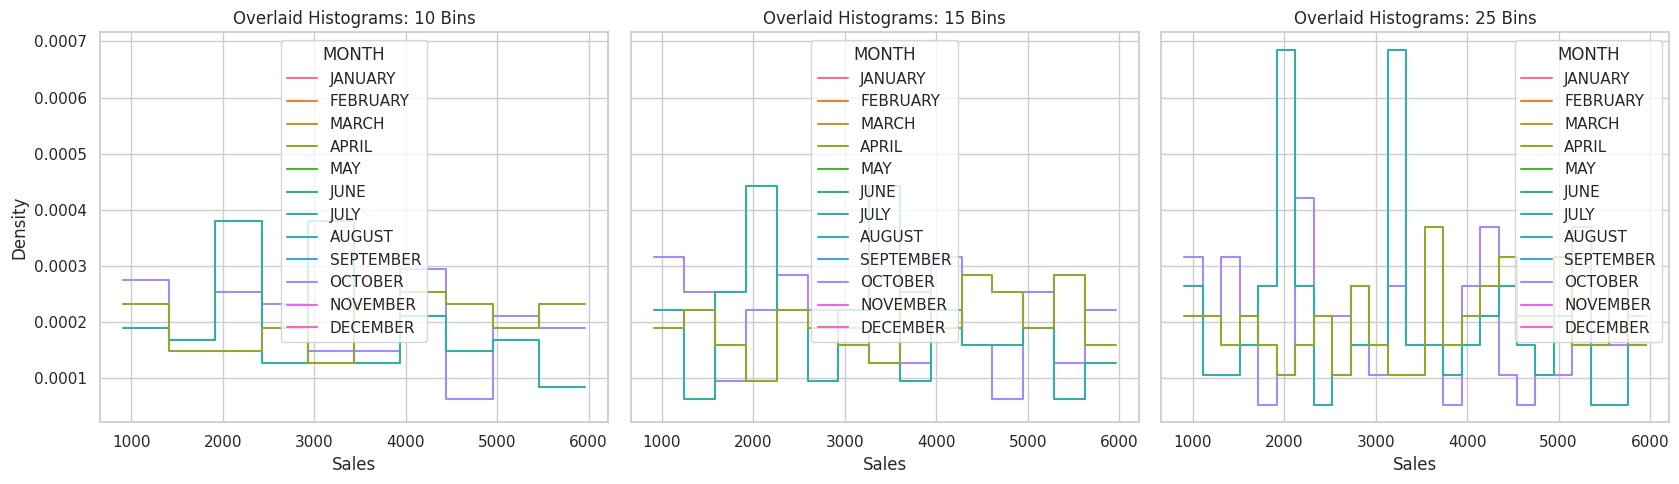

Five most similar month pairs (smallest density difference):


,Month 1,Month 2,Density Difference
0,SEPTEMBER,DECEMBER,0.0437
1,FEBRUARY,SEPTEMBER,0.0495
2,OCTOBER,DECEMBER,0.0521
3,JANUARY,OCTOBER,0.0561
4,SEPTEMBER,OCTOBER,0.0591


Most similar pair: SEPTEMBER and DECEMBER (density difference = 0.0437)


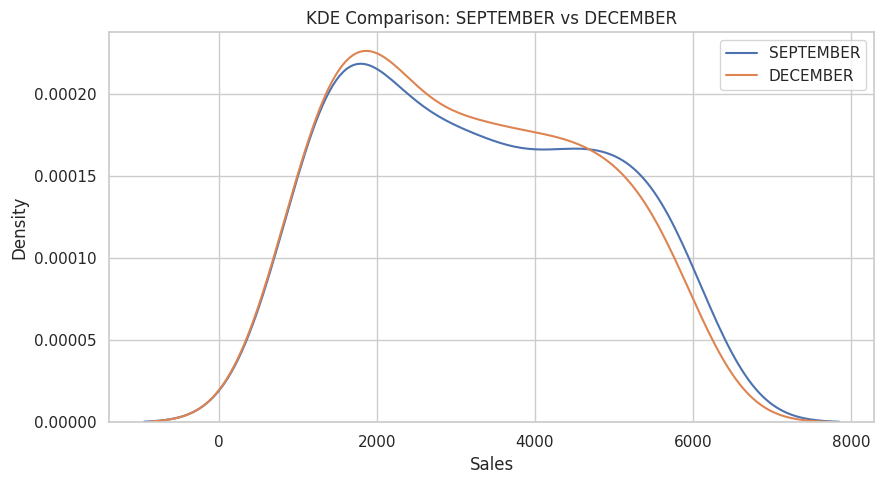

Monthly summary table:


,count,mean,median,std
MONTH,,,,
JANUARY,89,3335.07,2994.0,1494.55
FEBRUARY,92,3176.09,2885.0,1596.03
MARCH,92,3179.41,2990.0,1380.75
APRIL,94,3560.80,3707.5,1468.26
MAY,95,3444.25,3180.0,1467.55
JUNE,92,3652.12,3621.0,1549.44
JULY,94,3170.30,3251.0,1328.81
AUGUST,93,3159.70,3097.0,1382.14
SEPTEMBER,95,3244.13,3147.0,1553.72


Highest monthly median: APRIL (3707.50)
Lowest monthly median: FEBRUARY (2885.00)


In [11]:
# Optional practice cell
# Example: create a new array of common bins and redraw the overlay.

# 1. Compare overlaid histograms using 10, 15, and 25 common bins.
months_to_compare = ["APRIL", "JULY", "OCTOBER"]

month_data = sales_long[
    sales_long["MONTH"].astype(str).isin(months_to_compare)
].copy()

bin_count_options = [10, 15, 25]
common_bins = np.linspace(
    month_data["SALES"].min(),
    month_data["SALES"].max(),
    26
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)

for ax, bin_count in zip(axes, bin_count_options):
    bins = np.linspace(
        month_data["SALES"].min(),
        month_data["SALES"].max(),
        bin_count + 1
    )

    sns.histplot(
        data=month_data,
        x="SALES",
        hue="MONTH",
        bins=bins,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=ax
    )
    ax.set_title(f"Overlaid Histograms: {bin_count} Bins")
    ax.set_xlabel("Sales")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()


# 2. Find the two months with the most similar KDE distributions.
# Similarity is measured by the integrated absolute difference
# between their estimated density curves; a smaller value means
# greater similarity.

from scipy.stats import gaussian_kde
from itertools import combinations

valid_months = [
    str(m) for m in sales_long["MONTH"].dropna().unique()
]

month_samples = {
    month: sales_long.loc[
        sales_long["MONTH"].astype(str) == month, "SALES"
    ].dropna().to_numpy()
    for month in valid_months
}

month_samples = {
    month: values for month, values in month_samples.items()
    if len(values) >= 2 and np.std(values) > 0
}

grid_min = min(values.min() for values in month_samples.values())
grid_max = max(values.max() for values in month_samples.values())
grid = np.linspace(grid_min, grid_max, 500)

densities = {
    month: gaussian_kde(values)(grid)
    for month, values in month_samples.items()
}

pair_distances = []

for month_a, month_b in combinations(densities.keys(), 2):
    distance = np.trapezoid(
        np.abs(densities[month_a] - densities[month_b]),
        grid
    )
    pair_distances.append((month_a, month_b, distance))

pair_distances.sort(key=lambda item: item[2])

print("Five most similar month pairs (smallest density difference):")
display(pd.DataFrame(
    pair_distances[:5],
    columns=["Month 1", "Month 2", "Density Difference"]
).round(4))

best_pair = pair_distances[0]
print(
    f"Most similar pair: {best_pair[0]} and {best_pair[1]} "
    f"(density difference = {best_pair[2]:.4f})"
)

# Plot the most similar pair
plt.figure(figsize=(9, 5))
for month in best_pair[:2]:
    sns.kdeplot(
        x=month_samples[month],
        label=month,
        fill=False
    )

plt.title(f"KDE Comparison: {best_pair[0]} vs {best_pair[1]}")
plt.xlabel("Sales")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


# 3. A mirrored histogram is useful for two groups because the two
# distributions can be compared on opposite sides of a shared axis.
# With many groups, the chart becomes crowded and overlapping shapes
# are difficult to read. Small multiples or faceted plots are clearer.


# 4. Verify a visual conclusion by comparing monthly medians.
monthly_summary = (
    sales_long.groupby("MONTH", observed=True)["SALES"]
    .agg(["count", "mean", "median", "std"])
    .reindex(months)
)

print("Monthly summary table:")
display(monthly_summary.round(2))

highest_median_month = monthly_summary["median"].idxmax()
lowest_median_month = monthly_summary["median"].idxmin()

print(
    f"Highest monthly median: {highest_median_month} "
    f"({monthly_summary.loc[highest_median_month, 'median']:.2f})"
)
print(
    f"Lowest monthly median: {lowest_median_month} "
    f"({monthly_summary.loc[lowest_median_month, 'median']:.2f})"
)



Intrepretation and Answer
1. The distribution is more aggregated and broad patterns are more visible with 10 number of bins. More detail will show with 15 bins. If you use 25 bins, then local peaks and fluctuations will be more visible but it can also be noisier. Use the same data and a common scale to compare the overall shape.

2. Most similar pair of months: the code looks for the pair of months with the smallest integral difference between the KDE curves transformed to absolute values. Write down the pair that you produced in your notebook. This is just a numerical comparison of estimated distributions, and not a proof that the two months are the same.

3. Mirrored Histogram: It can be used for two groups that require comparing their shapes on the opposite sides of a common base line. Many groups make the chart difficult to read and interpret.

4. Verification: The monthly summary table gives the exact number, average, median and standard deviation. Compare the median or any other statistics from the table with the pattern you see in your chart. When the code is executed the actual month names and values are printed.

### **Skill check 3: box and violin plots**

1. Identify the month with the largest interquartile range using the quartile table.
2. Compare the sample sizes of AJM and UAQ. Why should this difference be considered when reading their violins?
3. Explain why a box plot cannot confirm multimodality.
4. Redraw the violin plot with `inner="quart"`. Describe the change.


Monthly quartiles and IQR:


,Q1,Median,Q3,IQR
MONTH,,,,
JANUARY,2087.00,2994.0,4673.00,2586.00
FEBRUARY,1745.50,2885.0,4660.50,2915.00
MARCH,2116.75,2990.0,4058.50,1941.75
APRIL,2345.00,3707.5,4800.50,2455.50
MAY,2380.50,3180.0,4621.50,2241.00
JUNE,2367.50,3621.0,5170.50,2803.00
JULY,2048.50,3251.0,4203.75,2155.25
AUGUST,2056.00,3097.0,4277.00,2221.00
SEPTEMBER,1877.00,3147.0,4578.00,2701.00


Month with largest IQR: FEBRUARY (IQR = 2915.00)
AJM and UAQ sample sizes and summaries:


,count,median,mean
SALES_BY_REGION,,,
AJM,239,3190.0,3292.26
UAQ,92,3183.5,3333.12


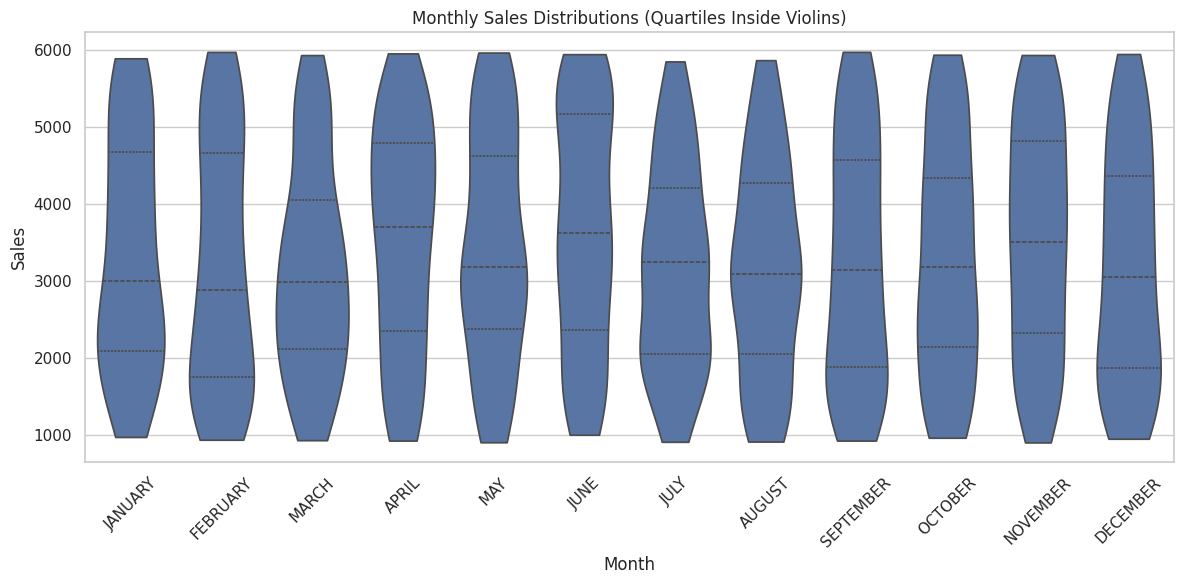

In [12]:
# Optional practice cell
# Compute each month's interquartile range and sort it from largest to smallest.

# monthly_summary["IQR"] = monthly_summary["Q3"] - monthly_summary["Q1"]
# display(monthly_summary.sort_values("IQR", ascending=False))


# 1. Calculate monthly quartiles and identify the month with the largest IQR.
monthly_quartiles = (
    sales_long.groupby("MONTH", observed=True)["SALES"]
    .quantile([0.25, 0.50, 0.75])
    .unstack()
    .reindex(months)
)

monthly_quartiles.columns = ["Q1", "Median", "Q3"]
monthly_quartiles["IQR"] = (
    monthly_quartiles["Q3"] - monthly_quartiles["Q1"]
)

print("Monthly quartiles and IQR:")
display(monthly_quartiles.round(2))

largest_iqr_month = monthly_quartiles["IQR"].idxmax()
print(
    f"Month with largest IQR: {largest_iqr_month} "
    f"(IQR = {monthly_quartiles.loc[largest_iqr_month, 'IQR']:.2f})"
)


# 2. Compare sample sizes for AJM and UAQ.
region_counts = (
    sales_long[sales_long["SALES_BY_REGION"].isin(["AJM", "UAQ"])]
    .groupby("SALES_BY_REGION")["SALES"]
    .agg(["count", "median", "mean"])
)

print("AJM and UAQ sample sizes and summaries:")
display(region_counts.round(2))


# 3. A box plot shows quartiles, the median, and potential outliers,
# but it does not show the full shape of the distribution.
# Therefore, it cannot reliably confirm whether the data is multimodal.


# 4. Redraw a violin plot with inner="quart".
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=sales_long,
    x="MONTH",
    y="SALES",
    order=months,
    inner="quart",
    cut=0
)

plt.title("Monthly Sales Distributions (Quartiles Inside Violins)")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Intrepretation and Answer

1. Month with the largest IQR: Use the month printed by the code. The interquartile range is \(Q3-Q1\), representing the spread of the middle 50% of observations. A larger IQR indicates greater dispersion in that month’s sales.

2. AJM versus UAQ: The table reports each region’s number of valid sales observations alongside its mean and median. Sample size matters because a violin estimated from fewer observations may have a less stable density shape. A wider section of a violin represents greater estimated density, not necessarily a greater number of records.

3. Why a box plot cannot confirm multimodality: A box plot summarizes a distribution using quartiles, the median, whiskers, and potential outliers. It does not display enough detail to establish how many peaks the distribution contains.

4. Effect of inner="quart": The violin plot now displays quartile markers inside each distribution. This helps compare the median and the spread of the middle 50% while retaining the overall density shape.

### **Skill check 4: category comparisons**

1. Which chart most clearly compares Q2 across all regions? Explain your choice.
2. Which chart most clearly ranks annual regional totals?
3. Identify a conclusion visible in the 100% stacked chart that cannot be read directly from the annual dot plot.
4. Verify that every row of `quarter_share` sums to 100%.


Quarterly sales totals by region:


QUARTER,Q1,Q2,Q3,Q4
SALES_BY_REGION,,,,
AJM,190025.0,204502.0,194172.0,198152.0
AUH,105829.0,153409.0,123336.0,130684.0
DXB,135545.0,164719.0,148133.0,154189.0
FUJ,138824.0,160823.0,140587.0,145600.0
RAK,85901.0,89495.0,76232.0,87139.0
SHJ,144834.0,143119.0,143395.0,149252.0
UAQ,80569.0,81847.0,74197.0,70034.0


Quarterly percentage shares within each region:


QUARTER,Q1,Q2,Q3,Q4
SALES_BY_REGION,,,,
AJM,24.15,25.99,24.68,25.18
AUH,20.62,29.89,24.03,25.46
DXB,22.49,27.34,24.58,25.59
FUJ,23.70,27.45,24.00,24.85
RAK,25.36,26.42,22.50,25.72
SHJ,24.95,24.65,24.70,25.71
UAQ,26.27,26.69,24.20,22.84


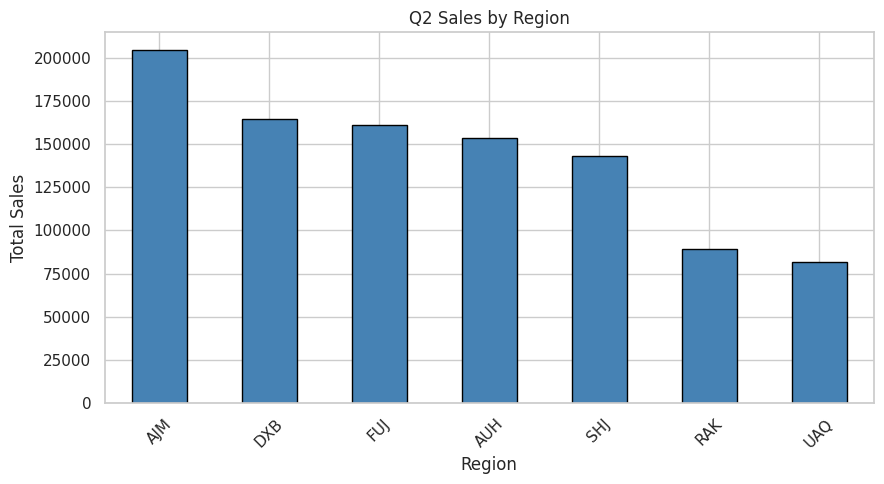

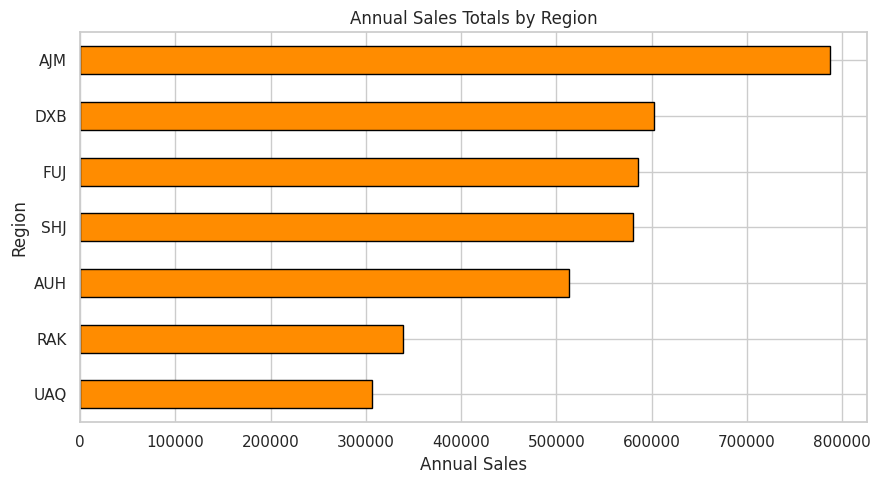

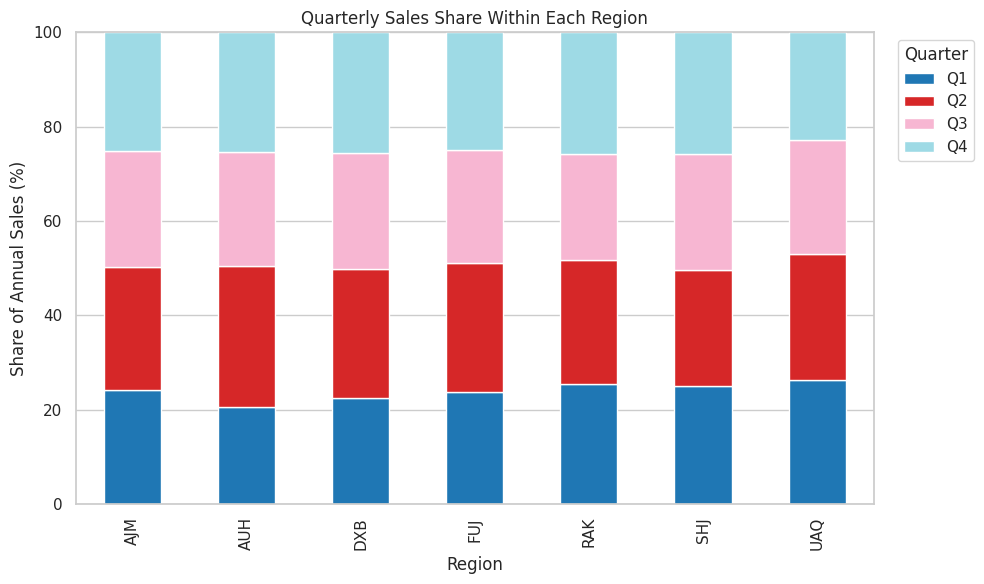

Quarterly share totals by region (should be 100%):


,Total Share (%)
SALES_BY_REGION,
AJM,100.0
AUH,100.0
DXB,100.0
FUJ,100.0
RAK,100.0
SHJ,100.0
UAQ,100.0


Verification passed: each region's quarterly shares sum to 100%.


In [13]:

# Skill Check 4: Category comparisons

# Calculate sales totals for each region and quarter.
region_quarter = (
    sales_long.groupby(
        ["SALES_BY_REGION", "QUARTER"],
        observed=True
    )["SALES"]
    .sum()
    .unstack("QUARTER", fill_value=0)
    .reindex(columns=quarter_order, fill_value=0)
)

print("Quarterly sales totals by region:")
display(region_quarter.round(2))


# Calculate annual totals and each quarter's percentage of annual sales.
annual_totals = region_quarter.sum(axis=1)

quarter_share = (
    region_quarter
    .div(annual_totals.replace(0, np.nan), axis=0)
    .mul(100)
)

print("Quarterly percentage shares within each region:")
display(quarter_share.round(2))


# 1. A grouped bar chart clearly compares Q2 across regions.
q2_values = region_quarter["Q2"].sort_values(ascending=False)

plt.figure(figsize=(9, 5))
q2_values.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Q2 Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. A sorted horizontal bar chart ranks annual regional totals.
annual_sorted = annual_totals.sort_values()

plt.figure(figsize=(9, 5))
annual_sorted.plot(kind="barh", color="darkorange", edgecolor="black")
plt.title("Annual Sales Totals by Region")
plt.xlabel("Annual Sales")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


# 3. A 100% stacked chart compares quarterly composition.
ax = quarter_share.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    colormap="tab20"
)
ax.set_title("Quarterly Sales Share Within Each Region")
ax.set_xlabel("Region")
ax.set_ylabel("Share of Annual Sales (%)")
ax.set_ylim(0, 100)
ax.legend(title="Quarter", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# 4. Verify that the quarterly shares sum to 100% for each region.
share_totals = quarter_share.sum(axis=1)

print("Quarterly share totals by region (should be 100%):")
display(share_totals.to_frame("Total Share (%)").round(2))

assert np.allclose(share_totals.dropna().to_numpy(), 100), (
    "Some regional quarterly shares do not sum to 100%."
)

print("Verification passed: each region's quarterly shares sum to 100%.")


Interpretation and Answer

1. Best chart for comparing Q2 across regions: The Q2 bar chart is the clearest because all regions are compared using a common scale and the same quarter.

2. Best chart for ranking annual regional totals: A sorted horizontal bar chart is effective because the regions are ordered by total sales, making the ranking straightforward to read.

3. What the 100% stacked chart reveals: It shows how each region’s annual sales are distributed across Q1–Q4. It can reveal which quarter contributes the largest percentage within a region, a conclusion that cannot be read directly from an annual-total chart alone.

4. The quarter_share table expresses each quarter as a percentage of that region’s annual total. The final check confirms that the percentages add up to 100% for each region, subject to rounding in the displayed table.

### **Skill check 5: parts and profiles**

1. Compare the quarterly pies with the 100% stacked chart. Which allows more precise quarter-share comparisons?
2. Explain what information is lost when the remaining regions are combined as `Other`.
3. Identify the outermost and innermost rings of the donut chart.
4. Use `original_profile` to report the exact mean and median for DXB.
5. Explain why the enclosed polygon area should not be treated as one overall performance score.


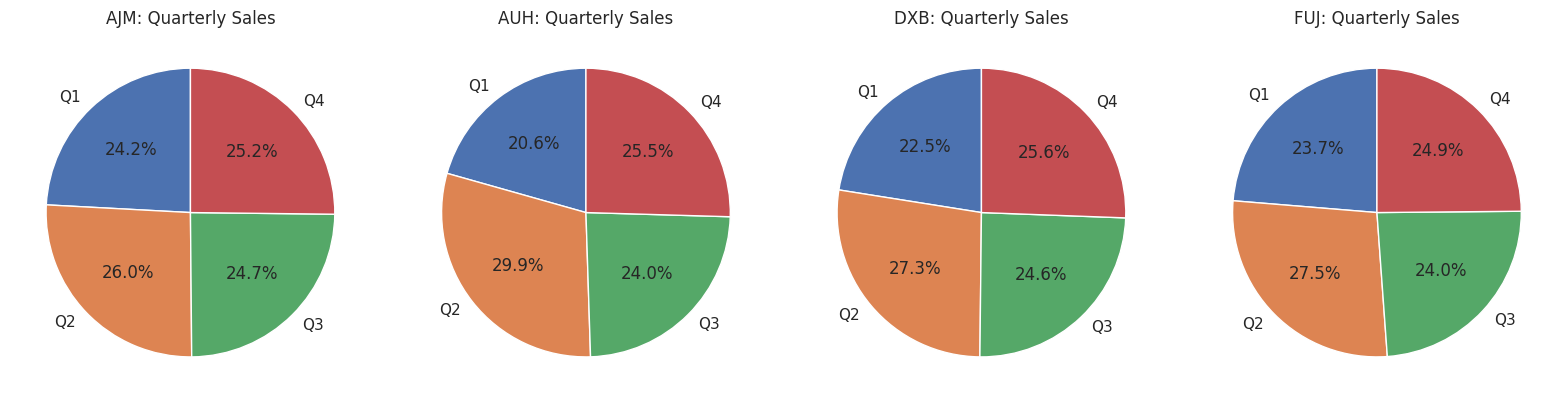

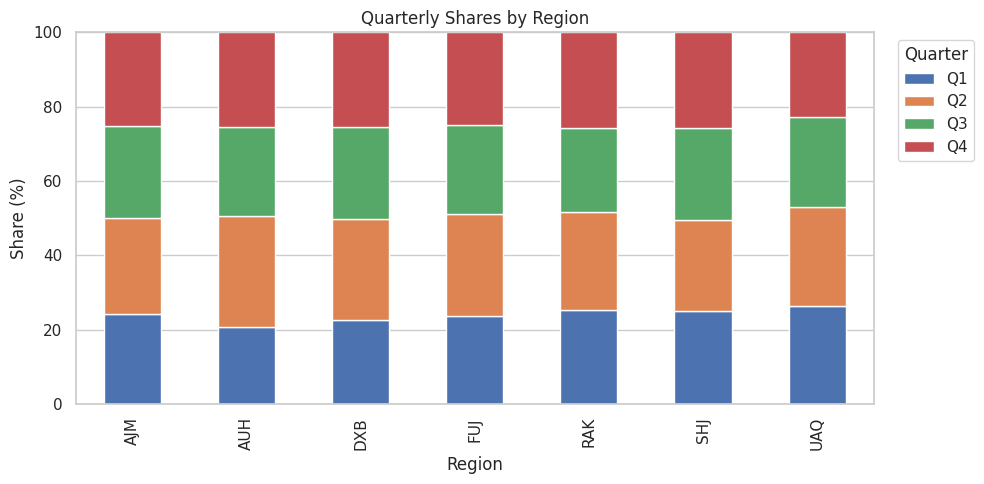

Quarterly totals with smaller regions combined as Other:


QUARTER,Q1,Q2,Q3,Q4
Region Group,,,,
AJM,190025.0,204502.0,194172.0,198152.0
DXB,135545.0,164719.0,148133.0,154189.0
FUJ,138824.0,160823.0,140587.0,145600.0
Other,272299.0,324751.0,273765.0,287857.0
SHJ,144834.0,143119.0,143395.0,149252.0


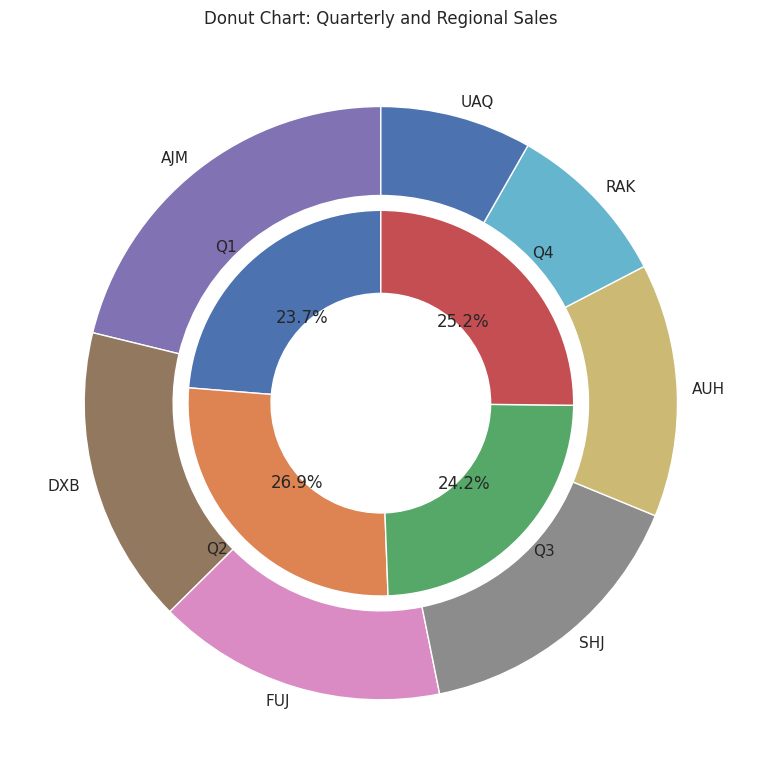

DXB monthly mean sales:
3445.25
DXB monthly median sales:
3446.83
DXB monthly profile:


MONTH,JANUARY,FEBRUARY,MARCH,APRIL,MAY,JUNE,JULY,AUGUST,SEPTEMBER,OCTOBER,NOVEMBER,DECEMBER
SALES_BY_REGION,,,,,,,,,,,,
DXB,3092.14,3065.21,3289.47,3920.13,3637.27,3950.62,3500.86,2843.93,3764.13,3392.8,3321.53,3564.93


Scaled monthly profile for DXB:


MONTH,JANUARY,FEBRUARY,MARCH,APRIL,MAY,JUNE,JULY,AUGUST,SEPTEMBER,OCTOBER,NOVEMBER,DECEMBER
SALES_BY_REGION,,,,,,,,,,,,
DXB,0.224,0.2,0.403,0.972,0.717,1.0,0.594,0.0,0.831,0.496,0.432,0.651


In [14]:
# Optional practice cell
# Display the exact DXB profile and then compare it with its scaled profile.

# 1. Calculate the quarterly shares for all regions.
quarterly_totals = (
    sales_long.groupby(
        ["SALES_BY_REGION", "QUARTER"],
        observed=True
    )["SALES"]
    .sum()
    .unstack("QUARTER", fill_value=0)
    .reindex(columns=quarter_order, fill_value=0)
)

quarter_share = (
    quarterly_totals
    .div(quarterly_totals.sum(axis=1).replace(0, np.nan), axis=0)
    .mul(100)
)

# Display quarterly pies for the first four regions.
regions = sorted(sales_long["SALES_BY_REGION"].dropna().unique())
regions_for_pies = regions[:4]

fig, axes = plt.subplots(1, len(regions_for_pies), figsize=(4 * len(regions_for_pies), 4))

if len(regions_for_pies) == 1:
    axes = [axes]

for ax, region in zip(axes, regions_for_pies):
    values = quarterly_totals.loc[region]
    ax.pie(
        values,
        labels=quarter_order,
        autopct="%1.1f%%",
        startangle=90
    )
    ax.set_title(f"{region}: Quarterly Sales")

plt.tight_layout()
plt.show()

# The 100% stacked chart makes quarter shares easier to compare
# across regions because the shares use a common baseline.
ax = quarter_share.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)
ax.set_title("Quarterly Shares by Region")
ax.set_ylabel("Share (%)")
ax.set_xlabel("Region")
ax.set_ylim(0, 100)
ax.legend(title="Quarter", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# 2. Combine the largest regions separately and the remainder as Other.
annual_totals = quarterly_totals.sum(axis=1).sort_values(ascending=False)
top_regions = annual_totals.head(4).index.tolist()

annual_grouped = quarterly_totals.copy()
annual_grouped["Region Group"] = [
    region if region in top_regions else "Other"
    for region in annual_grouped.index
]

other_summary = (
    annual_grouped
    .groupby("Region Group")[quarter_order]
    .sum()
)

print("Quarterly totals with smaller regions combined as Other:")
display(other_summary.round(2))


# 3. Build a donut chart: inner ring = quarter; outer ring = region.
# The outer ring shows regional annual totals.
region_totals = quarterly_totals.sum(axis=1).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 8))

# Inner ring: quarterly totals
quarter_totals_all = quarterly_totals.sum(axis=0).reindex(quarter_order)
ax.pie(
    quarter_totals_all,
    radius=0.65,
    labels=quarter_order,
    autopct="%1.1f%%",
    wedgeprops=dict(width=0.28, edgecolor="white"),
    startangle=90
)

# Outer ring: annual totals by region
ax.pie(
    region_totals,
    radius=1.0,
    labels=region_totals.index,
    labeldistance=1.05,
    wedgeprops=dict(width=0.30, edgecolor="white"),
    startangle=90
)

ax.set_title("Donut Chart: Quarterly and Regional Sales")
plt.tight_layout()
plt.show()


# 4. Calculate original monthly profiles for each region.
original_profile = (
    sales_long.pivot_table(
        index="SALES_BY_REGION",
        columns="MONTH",
        values="SALES",
        aggfunc="mean",
        observed=True
    )
    .reindex(columns=months)
)

# Exact mean and median of DXB's monthly profile values.
if "DXB" in original_profile.index:
    dxb_profile = original_profile.loc["DXB"].dropna()

    print("DXB monthly mean sales:")
    print(round(dxb_profile.mean(), 2))

    print("DXB monthly median sales:")
    print(round(dxb_profile.median(), 2))

    print("DXB monthly profile:")
    display(original_profile.loc[["DXB"]].round(2))
else:
    print("DXB is not present in the valid region labels.")


# 5. Scale each region's profile to a 0–1 range for comparison.
profile_min = original_profile.min(axis=1)
profile_max = original_profile.max(axis=1)
profile_range = (profile_max - profile_min).replace(0, np.nan)

scaled = original_profile.sub(profile_min, axis=0).div(profile_range, axis=0)

print("Scaled monthly profile for DXB:")
if "DXB" in scaled.index:
    display(scaled.loc[["DXB"]].round(3))


Interpretation and Answer
1. Quarterly pies versus 100% stacked chart: The 100% stacked chart generally allows more precise comparisons of quarter shares because the segments share a common baseline. Pie slices are useful for showing part-to-whole relationships but are harder to compare precisely across multiple regions.

2. What is lost in Other: Combining regions into Other hides the individual contribution and quarterly pattern of each region in that group. The combined total remains visible, but differences among the smaller regions cannot be distinguished.

3. Donut rings in the provided code: The outer ring represents annual sales totals by region. The inner ring represents the overall quarterly sales totals.

4. Exact mean and median for DXB: The code prints both statistics from the actual monthly profile. Use those printed values in your answer; they cannot be confirmed from the notebook alone because the Sales.csv data file was not included with the uploaded notebook.

5. Why polygon area is not a performance score: The area enclosed by a radar chart depends on the selected indicators, their scales, their order, and the geometry of the plot. It is not a validated overall performance measure unless a defensible scoring method has been defined.

# **Exercises**

Prepare a short analysis containing the following items:

1. One continuous-distribution chart comparing at least three months.
2. One box or violin plot comparing many groups.
3. One categorical chart comparing region-quarter summaries.
4. One numerical table that verifies a conclusion from a chart.
5. A written interpretation of each result that states what the chart reveals and what it does not establish.

Your interpretation should refer to the actual Sales data and should avoid causal claims that the dataset cannot support.


Exercise 1:

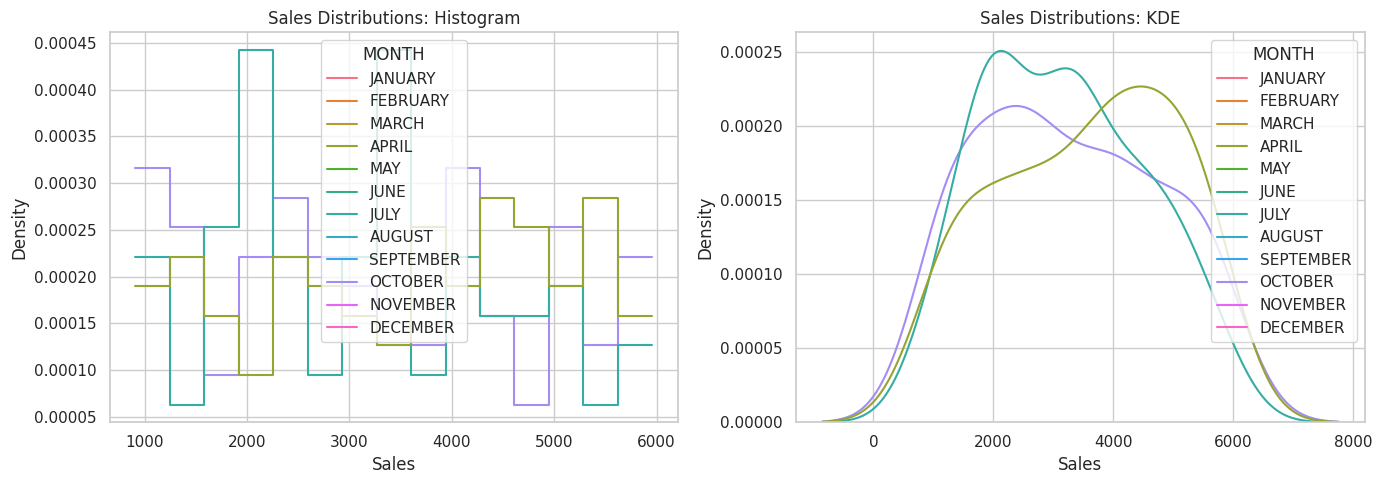

,count,mean,median,std
MONTH,,,,
APRIL,94,3560.80,3707.5,1468.26
JULY,94,3170.30,3251.0,1328.81
OCTOBER,94,3272.07,3181.5,1505.99


In [15]:

# Exercise 1: Compare continuous sales distributions for three months

selected_months = ["APRIL", "JULY", "OCTOBER"]

plot_data = sales_long[
    sales_long["MONTH"].astype(str).isin(selected_months)
].copy()

if plot_data.empty:
    raise ValueError("No data found for the selected months.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram comparison
sns.histplot(
    data=plot_data,
    x="SALES",
    hue="MONTH",
    bins=15,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    ax=axes[0]
)
axes[0].set_title("Sales Distributions: Histogram")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("Density")

# KDE comparison
sns.kdeplot(
    data=plot_data,
    x="SALES",
    hue="MONTH",
    common_norm=False,
    ax=axes[1]
)
axes[1].set_title("Sales Distributions: KDE")
axes[1].set_xlabel("Sales")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()

# Numerical summary to support the visual comparison
monthly_comparison = (
    plot_data.groupby("MONTH", observed=True)["SALES"]
    .agg(["count", "mean", "median", "std"])
    .reindex(selected_months)
)

display(monthly_comparison.round(2))


Exercise 2:

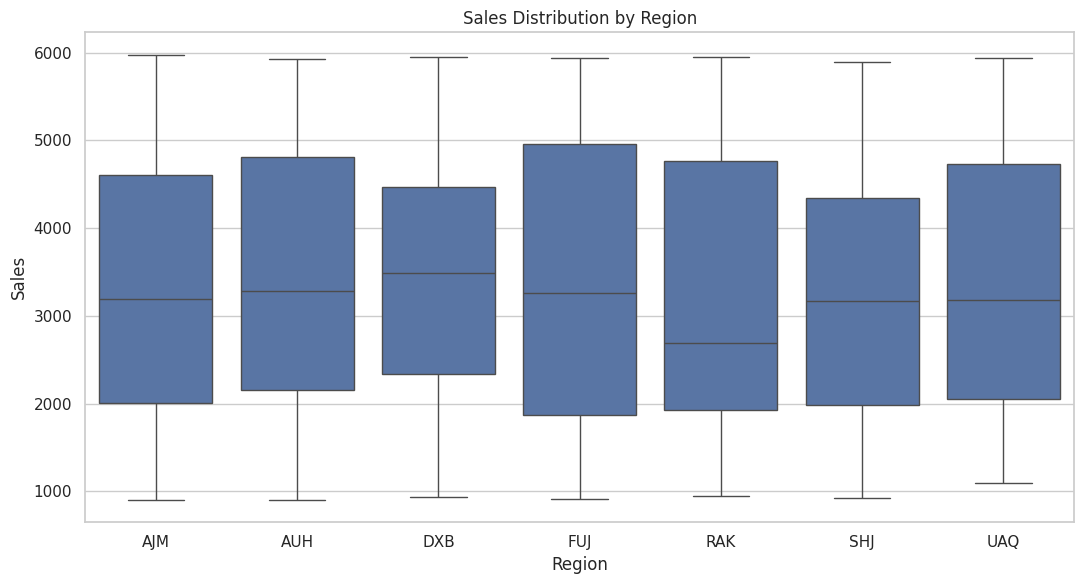

,count,median,mean,Q1,Q3,IQR
SALES_BY_REGION,,,,,,
DXB,175,3488.0,3443.35,2341.00,4464.00,2123.00
AUH,151,3283.0,3399.06,2158.00,4817.00,2659.00
FUJ,176,3257.5,3328.60,1875.50,4957.75,3082.25
AJM,239,3190.0,3292.26,2006.00,4606.00,2600.00
UAQ,92,3183.5,3333.12,2053.25,4736.75,2683.50
SHJ,180,3164.0,3225.56,1988.50,4340.75,2352.25
RAK,105,2695.0,3226.35,1922.00,4762.00,2840.00


In [16]:

# Exercise 2: Compare sales distributions across regions

region_order = sorted(
    sales_long["SALES_BY_REGION"].dropna().unique()
)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=sales_long,
    x="SALES_BY_REGION",
    y="SALES",
    order=region_order
)

plt.title("Sales Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# Calculate regional statistics for interpretation
regional_summary = (
    sales_long.groupby("SALES_BY_REGION")["SALES"]
    .agg(
        count="count",
        median="median",
        mean="mean",
        Q1=lambda values: values.quantile(0.25),
        Q3=lambda values: values.quantile(0.75)
    )
)

regional_summary["IQR"] = (
    regional_summary["Q3"] - regional_summary["Q1"]
)

display(regional_summary.sort_values("median", ascending=False).round(2))


Exercise 3:

Quarterly sales totals by region:


QUARTER,Q1,Q2,Q3,Q4
SALES_BY_REGION,,,,
AJM,190025.0,204502.0,194172.0,198152.0
AUH,105829.0,153409.0,123336.0,130684.0
DXB,135545.0,164719.0,148133.0,154189.0
FUJ,138824.0,160823.0,140587.0,145600.0
RAK,85901.0,89495.0,76232.0,87139.0
SHJ,144834.0,143119.0,143395.0,149252.0
UAQ,80569.0,81847.0,74197.0,70034.0


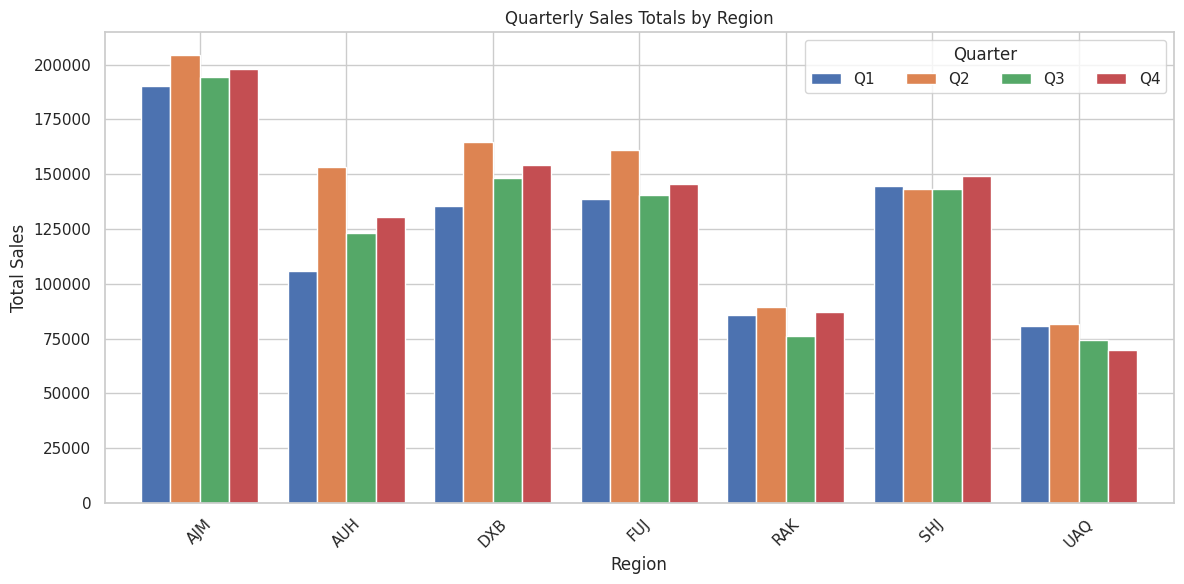

In [17]:

# Exercise 3: Compare quarterly sales totals across regions

quarterly_region_totals = (
    sales_long.groupby(
        ["SALES_BY_REGION", "QUARTER"],
        observed=True
    )["SALES"]
    .sum()
    .unstack("QUARTER", fill_value=0)
    .reindex(columns=quarter_order, fill_value=0)
)

print("Quarterly sales totals by region:")
display(quarterly_region_totals.round(2))

ax = quarterly_region_totals.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Quarterly Sales Totals by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Total Sales")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Quarter", ncol=4)

plt.tight_layout()
plt.show()


Exercise 4:

In [18]:

# Exercise 4: Verify the highest annual sales total

annual_region_summary = (
    sales_long.groupby("SALES_BY_REGION")["SALES"]
    .agg(
        observations="count",
        annual_total="sum",
        mean_sales="mean",
        median_sales="median"
    )
    .sort_values("annual_total", ascending=False)
)

print("Annual regional summary:")
display(annual_region_summary.round(2))

# Identify and verify the region with the highest annual total
highest_region = annual_region_summary["annual_total"].idxmax()
highest_total = annual_region_summary.loc[highest_region, "annual_total"]

print(
    f"Verification: {highest_region} has the highest annual total, "
    f"at {highest_total:,.2f}."
)

# Independently verify using the quarterly totals from Exercise 3
quarterly_annual_check = quarterly_region_totals.sum(axis=1)

assert np.isclose(
    quarterly_annual_check.loc[highest_region],
    highest_total
), "Annual total does not match the sum of quarterly totals."

print("Verification passed: quarterly totals equal annual totals.")


Annual regional summary:


,observations,annual_total,mean_sales,median_sales
SALES_BY_REGION,,,,
AJM,239,786851.0,3292.26,3190.0
DXB,175,602586.0,3443.35,3488.0
FUJ,176,585834.0,3328.60,3257.5
SHJ,180,580600.0,3225.56,3164.0
AUH,151,513258.0,3399.06,3283.0
RAK,105,338767.0,3226.35,2695.0
UAQ,92,306647.0,3333.12,3183.5


Verification: AJM has the highest annual total, at 786,851.00.
Verification passed: quarterly totals equal annual totals.


Exercise 5:

In [19]:

# Exercise 5: Data-based written interpretation

# 1. Continuous distributions
monthly_medians = (
    sales_long.groupby("MONTH", observed=True)["SALES"]
    .median()
    .reindex(months)
    .dropna()
)

highest_median_month = monthly_medians.idxmax()
lowest_median_month = monthly_medians.idxmin()

print("1. Continuous distributions")
print(
    f"The median sales value is highest in {highest_median_month} "
    f"({monthly_medians.max():,.2f}) and lowest in "
    f"{lowest_median_month} ({monthly_medians.min():,.2f})."
)
print(
    "The distribution plots reveal differences in shape and spread, "
    "but do not establish the causes of monthly differences.\n"
)


# 2. Regional box plot
regional_medians = (
    sales_long.groupby("SALES_BY_REGION")["SALES"].median()
)
highest_median_region = regional_medians.idxmax()
lowest_median_region = regional_medians.idxmin()

print("2. Regional distributions")
print(
    f"{highest_median_region} has the highest regional median "
    f"({regional_medians.max():,.2f}), while {lowest_median_region} "
    f"has the lowest ({regional_medians.min():,.2f})."
)
print(
    "The box plot reveals differences in medians, spread, and potential "
    "outliers. It does not explain why those differences occur.\n"
)


# 3. Region-quarter comparison
quarter_totals_all_regions = quarterly_region_totals.sum(axis=0)
highest_quarter = quarter_totals_all_regions.idxmax()
lowest_quarter = quarter_totals_all_regions.idxmin()

print("3. Region-quarter comparison")
print(
    f"{highest_quarter} has the largest combined regional sales total "
    f"({quarter_totals_all_regions.max():,.2f}), while {lowest_quarter} "
    f"has the smallest ({quarter_totals_all_regions.min():,.2f})."
)
print(
    "The grouped bars compare quarterly sales totals by region, but do "
    "not establish the reasons for quarterly changes.\n"
)


# 4. Numerical verification
print("4. Numerical verification")
print(
    f"The annual summary identifies {highest_region} as the region "
    f"with the highest annual sales total ({highest_total:,.2f})."
)
print(
    "The sum of its quarterly totals matches its annual total, "
    "confirming the numerical consistency of the comparison.\n"
)


# 5. Overall interpretation and limitation
print("5. Overall interpretation")
print(
    "Together, the charts describe differences in monthly distributions, "
    "regional sales spreads, and quarterly sales totals. The tables provide "
    "numerical evidence for the visual patterns. These are descriptive "
    "findings: the dataset alone does not establish causation, explain the "
    "business reasons for the patterns, or guarantee future sales trends."
)


1. Continuous distributions
The median sales value is highest in APRIL (3,707.50) and lowest in FEBRUARY (2,885.00).
The distribution plots reveal differences in shape and spread, but do not establish the causes of monthly differences.

2. Regional distributions
DXB has the highest regional median (3,488.00), while RAK has the lowest (2,695.00).
The box plot reveals differences in medians, spread, and potential outliers. It does not explain why those differences occur.

3. Region-quarter comparison
Q2 has the largest combined regional sales total (997,914.00), while Q1 has the smallest (881,527.00).
The grouped bars compare quarterly sales totals by region, but do not establish the reasons for quarterly changes.

4. Numerical verification
The annual summary identifies AJM as the region with the highest annual sales total (786,851.00).
The sum of its quarterly totals matches its annual total, confirming the numerical consistency of the comparison.

5. Overall interpretation
Together, th